In [1]:
%pip install -q tensorflow-datasets importlib_resources

In [1]:
import random
from collections import Counter
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

SEED = 42                      # angka pengunci acak supaya hasil bisa diulang
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
KELAS = ["healthy", "cmd", "cbsd"]   # kelas yang dipakai (boleh diganti)

(train_raw, val_raw, test_raw), info = tfds.load(
    "cassava", split=["train", "validation", "test"],
    as_supervised=True, with_info=True)

nama_asli = [n.lower() for n in info.features["label"].names]
print("Nama kelas asli:", nama_asli)

# nomor asli tiap kelas yang dipilih
KEEP = tf.constant([nama_asli.index(k) for k in KELAS], dtype=tf.int64)

def pilih(ds):
    # 1) buang foto yang kelasnya tidak dipilih
    ds = ds.filter(lambda x, y: tf.reduce_any(tf.equal(y, KEEP)))
    # 2) ubah label asli menjadi 0, 1, 2 sesuai urutan KELAS
    ds = ds.map(lambda x, y: (x, tf.argmax(tf.cast(tf.equal(KEEP, y), tf.int32))))
    return ds

train_ds, val_ds, test_ds = pilih(train_raw), pilih(val_raw), pilih(test_raw)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-test.tfrecord-[0-9][0-9][0-9][0-9]…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-validation.tfrecord-[0-9][0-9][0-9…

Dataset cassava downloaded and prepared to /root/tensorflow_datasets/cassava/0.1.0. Subsequent calls will reuse this data.
Nama kelas asli: ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']


In [3]:
KELAS = ["healthy", "cmd", "cbsd"]   # kelas yang dipakai (boleh diganti)

(train_raw, val_raw, test_raw), info = tfds.load(
    "cassava", split=["train", "validation", "test"],
    as_supervised=True, with_info=True)

nama_asli = [n.lower() for n in info.features["label"].names]
print("Nama kelas asli:", nama_asli)

# nomor asli tiap kelas yang dipilih
KEEP = tf.constant([nama_asli.index(k) for k in KELAS], dtype=tf.int64)

def pilih(ds):
    # 1) buang foto yang kelasnya tidak dipilih
    ds = ds.filter(lambda x, y: tf.reduce_any(tf.equal(y, KEEP)))
    # 2) ubah label asli menjadi 0, 1, 2 sesuai urutan KELAS
    ds = ds.map(lambda x, y: (x, tf.argmax(tf.cast(tf.equal(KEEP, y), tf.int32))))
    return ds

train_ds, val_ds, test_ds = pilih(train_raw), pilih(val_raw), pilih(test_raw)

Nama kelas asli: ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']


train       {'healthy': 316, 'cmd': 2658, 'cbsd': 1443} total = 4417
validation  {'healthy': 106, 'cmd': 887, 'cbsd': 482} total = 1475
test        {'healthy': 105, 'cmd': 886, 'cbsd': 481} total = 1472


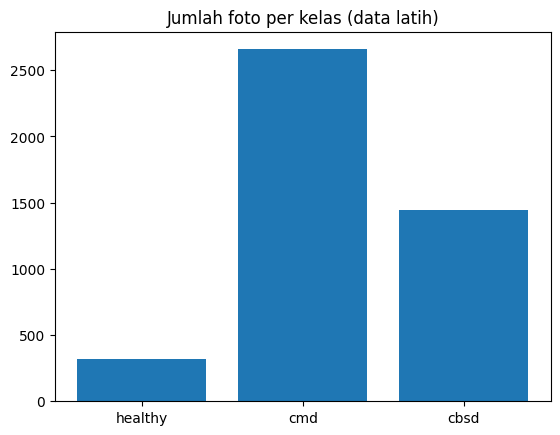

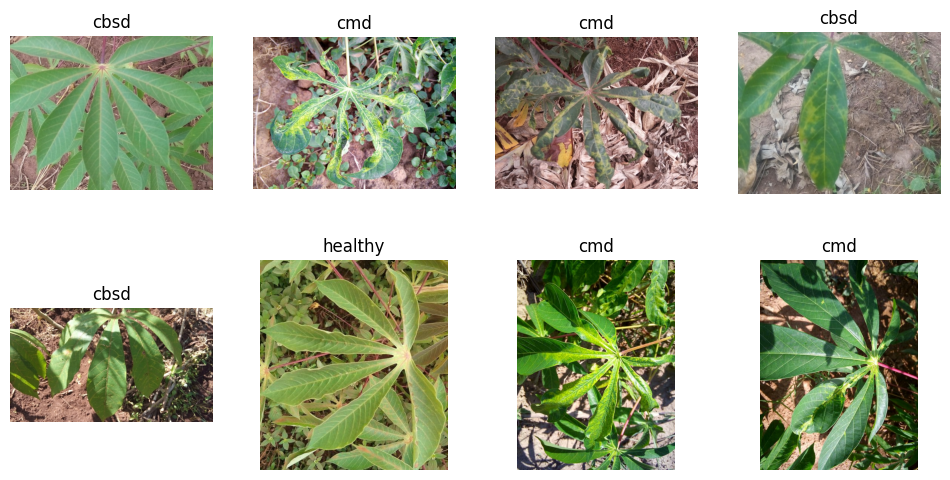

In [4]:
def hitung_kelas(ds):
    jumlah = Counter(int(y) for y in ds.map(lambda x, y: y))
    return [jumlah[i] for i in range(len(KELAS))]

jumlah = {"train": hitung_kelas(train_ds),
          "validation": hitung_kelas(val_ds),
          "test": hitung_kelas(test_ds)}
for nama, j in jumlah.items():
    print(nama.ljust(11), dict(zip(KELAS, j)), "total =", sum(j))

# grafik jumlah foto data latih
plt.bar(KELAS, jumlah["train"])
plt.title("Jumlah foto per kelas (data latih)")
plt.show()

# 8 contoh foto acak
plt.figure(figsize=(12, 6))
for i, (img, y) in enumerate(train_ds.shuffle(300, seed=SEED).take(8)):
    plt.subplot(2, 4, i + 1)
    plt.imshow(img.numpy())
    plt.title(KELAS[int(y)])
    plt.axis("off")
plt.show()

In [5]:
import os, shutil
from google.colab import files

UKURAN = None      # None = ukuran asli; isi (224, 224) bila ingin zip lebih kecil
FOLDER = "/content/dataset_png"
shutil.rmtree(FOLDER, ignore_errors=True)

def simpan(ds, nama_split):
    # buat folder: split / kelas
    for k in KELAS:
        os.makedirs(f"{FOLDER}/{nama_split}/{k}", exist_ok=True)
    for i, (img, y) in enumerate(ds):
        if UKURAN is not None:
            img = tf.image.resize_with_pad(img, *UKURAN)   # hasilnya desimal
            img = tf.cast(tf.round(img), tf.uint8)         # kembalikan ke 0-255
        k = KELAS[int(y)]
        path = f"{FOLDER}/{nama_split}/{k}/{nama_split}_{k}_{i:04d}.png"
        tf.io.write_file(path, tf.io.encode_png(img))      # simpan sebagai PNG
    print(nama_split, "selesai")

simpan(train_ds, "train")
simpan(val_ds, "validation")
simpan(test_ds, "test")

# kumpulkan semua jadi satu zip
hasil = shutil.make_archive("/content/dataset_daun_singkong_png", "zip", FOLDER)
print("Ukuran zip:", round(os.path.getsize(hasil) / 1e6, 1), "MB")
files.download(hasil)

train selesai
validation selesai
test selesai
Ukuran zip: 4865.2 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
IMG_SIZE = (128, 128)   # ukuran foto masuk ke model (lebih kecil dari 224 agar latihan cepat)
BATCH = 32              # jumlah foto yang diproses sekali jalan
AUTOTUNE = tf.data.AUTOTUNE

def siapkan(ds, acak=False):
    # ubah semua foto ke 128 x 128 tanpa merusak bentuk (diberi bingkai kosong)
    ds = ds.map(lambda x, y: (tf.image.resize_with_pad(x, *IMG_SIZE), y),
                num_parallel_calls=AUTOTUNE)
    ds = ds.cache()                      # simpan di memori supaya epoch berikutnya cepat
    if acak:
        ds = ds.shuffle(1000, seed=SEED) # kocok urutan foto latih
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_b = siapkan(train_ds, acak=True)
val_b = siapkan(val_ds)
test_b = siapkan(test_ds)

print("Data siap.")

Data siap.


In [7]:
from tensorflow import keras
from tensorflow.keras import layers

# augmentasi: hanya aktif saat latihan, otomatis mati saat evaluasi
augmentasi = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentasi")

def buat_cnn(jumlah_kelas):
    return keras.Sequential([
        keras.Input(shape=IMG_SIZE + (3,)),            # foto berwarna (3 lapisan warna)
        augmentasi,
        layers.Rescaling(1.0 / 255),                   # piksel 0-255 menjadi 0-1

        layers.Conv2D(16, 3, activation="relu", padding="same"),   # blok 1
        layers.MaxPooling2D(),
        layers.Conv2D(32, 3, activation="relu", padding="same"),   # blok 2
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu", padding="same"),   # blok 3
        layers.MaxPooling2D(),

        layers.Flatten(),                              # ratakan jadi satu baris angka
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.5),                           # cegah overfitting
        layers.Dense(jumlah_kelas, activation="softmax"),  # persentase tiap kelas
    ], name="cnn_daun_singkong")

model = buat_cnn(len(KELAS))
model.summary()

Model: "cnn_daun_singkong"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentasi (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,048,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,072,419 (4.09 MB)

 Trainable params: 1,072,419 (4.09 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# bobot kelas: kelas yang fotonya sedikit diberi bobot lebih besar
n_train = sum(jumlah["train"])
bobot = {i: n_train / (len(KELAS) * j) for i, j in enumerate(jumlah["train"])}
print("Bobot kelas:", {KELAS[i]: round(b, 2) for i, b in bobot.items()})

# aturan belajar
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",   # untuk label berupa angka 0, 1, 2
    metrics=["accuracy"],
)

callbacks = [
    # simpan model pada epoch terbaiknya
    keras.callbacks.ModelCheckpoint("best_model.keras", monitor="val_loss",
                                    save_best_only=True),
    # berhenti bila 5 epoch berturut-turut tidak membaik, lalu kembali ke yang terbaik
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                  restore_best_weights=True),
]

hist = model.fit(
    train_b,
    validation_data=val_b,
    epochs=30,
    class_weight=bobot,
    callbacks=callbacks,
)

Bobot kelas: {'healthy': 4.66, 'cmd': 0.55, 'cbsd': 1.02}
Epoch 1/30
    139/Unknown 28s 77ms/step - accuracy: 0.4856 - loss: 1.1250

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


139/139 ━━━━━━━━━━━━━━━━━━━━ 34s 117ms/step - accuracy: 0.5431 - loss: 1.0797 - val_accuracy: 0.7220 - val_loss: 0.8230
Epoch 2/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.6165 - loss: 1.0116 - val_accuracy: 0.7186 - val_loss: 0.8082
Epoch 3/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.6375 - loss: 0.9975 - val_accuracy: 0.6976 - val_loss: 0.7999
Epoch 4/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.6321 - loss: 0.9536 - val_accuracy: 0.7146 - val_loss: 0.7529
Epoch 5/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.6326 - loss: 0.9289 - val_accuracy: 0.7139 - val_loss: 0.6833
Epoch 6/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.6271 - loss: 0.9090 - val_accuracy: 0.7763 - val_loss: 0.6389
Epoch 7/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.6615 - loss: 0.8781 - val_accuracy: 0.7308 - val_loss: 0.6988
Epoch 8/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.6432 - loss: 0.8672 - val_accuracy: 0.

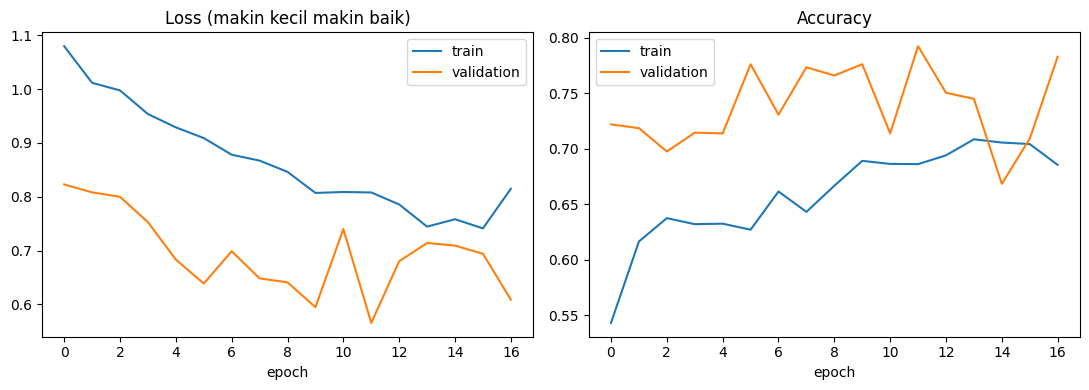

In [9]:
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(hist.history["loss"], label="train")
plt.plot(hist.history["val_loss"], label="validation")
plt.title("Loss (makin kecil makin baik)")
plt.xlabel("epoch"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist.history["accuracy"], label="train")
plt.plot(hist.history["val_accuracy"], label="validation")
plt.title("Accuracy")
plt.xlabel("epoch"); plt.legend()

plt.tight_layout()
plt.savefig("kurva_latihan.png", dpi=150)   # simpan untuk laporan
plt.show()

Accuracy          : 0.7846
Macro-F1          : 0.6296
Balanced accuracy : 0.6031

              precision    recall  f1-score   support

     healthy      0.439     0.276     0.339       105
         cmd      0.786     0.959     0.864       886
        cbsd      0.852     0.574     0.686       481

    accuracy                          0.785      1472
   macro avg      0.692     0.603     0.630      1472
weighted avg      0.783     0.785     0.768      1472



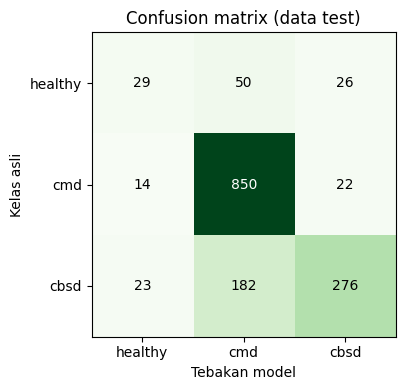

In [10]:
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, f1_score, balanced_accuracy_score)

# kumpulkan jawaban asli dan tebakan model untuk seluruh data test
y_true, y_pred = [], []
for x, y in test_b:
    p = model.predict(x, verbose=0)
    y_pred.extend(np.argmax(p, axis=1))   # kelas dengan skor tertinggi
    y_true.extend(y.numpy())

acc = accuracy_score(y_true, y_pred)
mf1 = f1_score(y_true, y_pred, average="macro")
bal = balanced_accuracy_score(y_true, y_pred)
print(f"Accuracy          : {acc:.4f}")
print(f"Macro-F1          : {mf1:.4f}")
print(f"Balanced accuracy : {bal:.4f}\n")
print(classification_report(y_true, y_pred, target_names=KELAS, digits=3))

# confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Greens")
plt.xticks(range(len(KELAS)), KELAS)
plt.yticks(range(len(KELAS)), KELAS)
for i in range(len(KELAS)):
    for j in range(len(KELAS)):
        warna = "white" if cm[i, j] > cm.max() / 2 else "black"
        plt.text(j, i, cm[i, j], ha="center", va="center", color=warna)
plt.xlabel("Tebakan model")
plt.ylabel("Kelas asli")
plt.title("Confusion matrix (data test)")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

{'kelas': ['healthy', 'cmd', 'cbsd'], 'jumlah_foto_test': 1472, 'test_accuracy': 0.7846, 'test_macro_f1': 0.6296, 'test_balanced_accuracy': 0.6031}


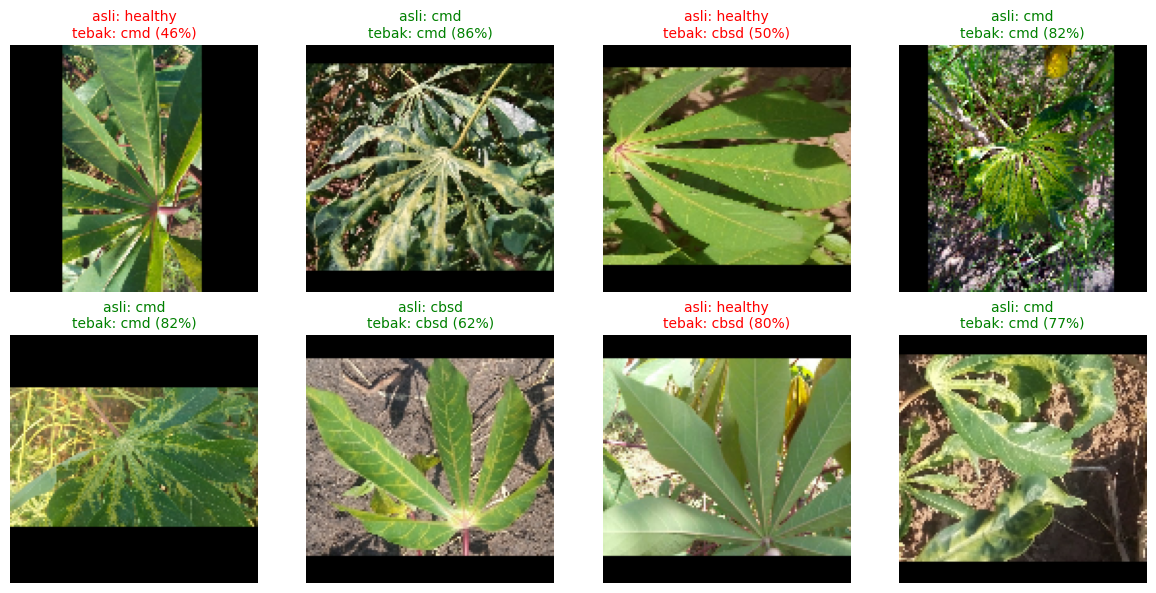

In [11]:
import json

hasil = {"kelas": KELAS, "jumlah_foto_test": len(y_true),
         "test_accuracy": round(float(acc), 4),
         "test_macro_f1": round(float(mf1), 4),
         "test_balanced_accuracy": round(float(bal), 4)}
with open("hasil_akhir.json", "w") as f:
    json.dump(hasil, f, indent=2)
print(hasil)

# 8 contoh foto test acak beserta tebakannya
x8, y8 = next(iter(test_b.unbatch().shuffle(500, seed=SEED).batch(8)))
p8 = model.predict(x8, verbose=0)
plt.figure(figsize=(12, 6))
for i in range(8):
    tebak = int(np.argmax(p8[i]))
    asli = int(y8[i])
    plt.subplot(2, 4, i + 1)
    plt.imshow(x8[i].numpy().astype("uint8"))
    plt.title(f"asli: {KELAS[asli]}\ntebak: {KELAS[tebak]} ({p8[i][tebak]:.0%})",
              color="green" if tebak == asli else "red", fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.savefig("contoh_prediksi.png", dpi=150)
plt.show()

In [12]:
import os, shutil, json
from google.colab import files

PAKET = "/content/paket_revisi"
shutil.rmtree(PAKET, ignore_errors=True)
for d in ["app_artifacts", "plots", "reports"]:
    os.makedirs(f"{PAKET}/{d}")

# 1) model terbaik dan keterangannya
shutil.copy("best_model.keras", f"{PAKET}/app_artifacts/best_model.keras")
with open(f"{PAKET}/app_artifacts/class_names.json", "w") as f:
    json.dump(KELAS, f)
with open(f"{PAKET}/app_artifacts/metadata.json", "w") as f:
    json.dump({"img_size": list(IMG_SIZE), "kelas": KELAS,
               "arsitektur": "CNN buatan sendiri (3 blok Conv2D + MaxPooling), dilatih dari nol"},
              f, indent=2)

# 2) grafik dan angka hasil
for nama in ["kurva_latihan.png", "confusion_matrix.png", "contoh_prediksi.png"]:
    shutil.copy(nama, f"{PAKET}/plots/")
shutil.copy("hasil_akhir.json", f"{PAKET}/reports/")

# 3) berkas aplikasi
APP = r'''import json
from pathlib import Path

import numpy as np
import tensorflow as tf
import gradio as gr

ART = Path(__file__).parent / "app_artifacts"
CLASS_NAMES = json.loads((ART / "class_names.json").read_text())
META = json.loads((ART / "metadata.json").read_text())
IMG_SIZE = tuple(META["img_size"])
model = tf.keras.models.load_model(ART / "best_model.keras")

BATAS = 0.50   # skor tertinggi di bawah batas ini dianggap bukan daun singkong


def prediksi(pil_image):
    if pil_image is None:
        return {}, "Unggah foto daun terlebih dahulu."
    arr = np.asarray(pil_image.convert("RGB"), dtype=np.float32)
    arr = tf.image.resize_with_pad(arr, *IMG_SIZE).numpy()
    probs = model.predict(arr[None, ...], verbose=0)[0]
    top = float(probs.max())
    if top < BATAS:
        return {}, f"Bukan termasuk kategori daun singkong! (skor tertinggi {top:.1%}, di bawah batas {BATAS:.0%})"
    skor = {CLASS_NAMES[i]: float(probs[i]) for i in range(len(CLASS_NAMES))}
    kelas = CLASS_NAMES[int(probs.argmax())]
    return skor, f"Prediksi: {kelas} (skor {top:.1%}). Ini bukan diagnosis definitif."


with gr.Blocks(title="Klasifikasi Daun Singkong") as demo:
    gr.Markdown("# Klasifikasi Penyakit Daun Singkong (CNN)\nUnggah foto daun singkong, lalu klik Klasifikasikan.")
    with gr.Row():
        inp = gr.Image(type="pil", label="Foto daun", sources=["upload", "webcam"])
        with gr.Column():
            out_label = gr.Label(num_top_classes=3, label="Skor tiap kelas")
            out_msg = gr.Textbox(label="Hasil")
    gr.Button("Klasifikasikan").click(prediksi, inp, [out_label, out_msg])

if __name__ == "__main__":
    demo.launch()
'''
with open(f"{PAKET}/app.py", "w") as f:
    f.write(APP)
with open(f"{PAKET}/requirements.txt", "w") as f:
    f.write("tensorflow\ngradio\npillow\nnumpy\n")

# 4) uji: apakah model bisa dimuat ulang dari paket?
uji = keras.models.load_model(f"{PAKET}/app_artifacts/best_model.keras")
print("Model bisa dimuat. Parameter:", uji.count_params(), "\n")

# 5) tampilkan isi paket, lalu zip dan unduh
for root, _, fs in os.walk(PAKET):
    for nama in fs:
        print(os.path.join(root, nama).replace(PAKET + "/", ""))
hasil_zip = shutil.make_archive("/content/paket_revisi", "zip", PAKET)
print("\nUkuran paket:", round(os.path.getsize(hasil_zip) / 1e6, 1), "MB")
files.download(hasil_zip)

Model bisa dimuat. Parameter: 1072419 

requirements.txt
app.py
plots/kurva_latihan.png
plots/confusion_matrix.png
plots/contoh_prediksi.png
app_artifacts/best_model.keras
app_artifacts/metadata.json
app_artifacts/class_names.json
reports/hasil_akhir.json

Ukuran paket: 13.1 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
!pip install -q gradio
%run /content/paket_revisi/app.py

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ed8e362a2f323fc6ad.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


<Figure size 640x480 with 0 Axes>

In [15]:
from sklearn.metrics import classification_report

# ---- angka otomatis dari hasil project ----
baris_data = ""
for i, k in enumerate(KELAS):
    t, v, s = jumlah["train"][i], jumlah["validation"][i], jumlah["test"][i]
    baris_data += f"| {k} | {t} | {v} | {s} | {t + v + s} |\n"
T, V, S = sum(jumlah["train"]), sum(jumlah["validation"]), sum(jumlah["test"])
baris_data += f"| **Total** | {T} | {V} | {S} | {T + V + S} |"

bobot_txt = ", ".join(f"{KELAS[i]} = {b:.2f}" for i, b in bobot.items())
laporan = classification_report(y_true, y_pred, target_names=KELAS, digits=3)
laporan = "\n".join("    " + baris for baris in laporan.splitlines())

README = r'''# Klasifikasi Penyakit Daun Singkong Menggunakan Convolutional Neural Network (CNN) pada Dataset iCassava 2019

Tugas Besar Kecerdasan Buatan, S1 Ilmu Komputer, FMIPA, Universitas Halu Oleo. Konteks proyek: SDG 2 (Tanpa Kelaparan).

## Anggota Kelompok

| Nama | NIM |
|---|---|
| RAIHAN AL RAJAB | ISI NIM |
| FATIMAH ALYA SABHIRAH | ISI NIM |
| ANGGUN DIAN MUTIARA | ISI NIM |

## Ringkasan

Proyek ini membangun sebuah CNN dari nol untuk mengklasifikasikan foto daun singkong ke dalam @@JK@@ kelas: @@KELAS@@. Seluruh bobot model dimulai dari angka acak dan dilatih sendiri. Proyek tidak memakai model pra-latih maupun arsitektur lain. Hasilnya dipakai sebagai prototipe skrining berbasis foto, bukan alat diagnosis.

## Latar Belakang dan SDG 2

Singkong adalah tanaman pangan penting di daerah tropis. Gejala penyakit pada daunnya sering mirip satu sama lain, sehingga sulit dibedakan hanya dengan mata. Skrining berbasis foto berpotensi mendukung pemantauan kesehatan tanaman pangan, yang berkaitan dengan target 2.4 SDG 2 (sistem produksi pangan berkelanjutan dan pertanian yang tangguh). Proyek ini tidak mengukur dampak pada hasil panen, jadi klaimnya dibatasi sebagai potensi dukungan pemantauan.

## Dataset

Dataset yang dipakai adalah **iCassava 2019** (Mwebaze et al., 2019), dimuat lewat TensorFlow Datasets dengan nama `cassava`. Dataset berisi foto daun singkong dari Uganda dengan lima kelas asli. Versi proyek ini memakai @@JK@@ kelas (@@KELAS@@) supaya klasifikasi lebih sederhana.

| Kode | Arti |
|---|---|
| CBB | Cassava Bacterial Blight (hawar bakteri) |
| CBSD | Cassava Brown Streak Disease (penyakit garis cokelat) |
| CGM | Cassava Green Mottle (belang hijau) |
| CMD | Cassava Mosaic Disease (penyakit mosaik) |
| Healthy | Daun sehat |

Jumlah foto per kelas (pembagian resmi dari TensorFlow Datasets):

| Kelas | Train | Validation | Test | Total |
|---|---|---|---|---|
@@BARIS_DATA@@

Catatan tentang data:

- Satu foto hanya memiliki satu label.
- Jumlah foto antarkelas tidak seimbang, sehingga bobot kelas dipakai saat pelatihan (@@BOBOT@@).
- Foto tidak disalin ke repositori ini. Dataset diunduh otomatis lewat kode berikut.

    import tensorflow_datasets as tfds
    train, val, test = tfds.load("cassava", split=["train", "validation", "test"], as_supervised=True)

Informasi sumber dan lisensi dataset: https://www.tensorflow.org/datasets/catalog/cassava

## Metode

### 1. Persiapan data

- Semua foto diubah ke 128 x 128 piksel dengan `tf.image.resize_with_pad`. Bentuk foto dijaga dan sisi yang kurang diberi bingkai kosong.
- Nilai piksel diubah dari 0-255 menjadi 0-1 lewat lapisan `Rescaling`.
- Foto dikelompokkan per 32 (batch), dengan seed acak 42.
- Augmentasi hanya aktif saat latihan: flip horizontal dan vertikal, rotasi acak (faktor 0,1), dan zoom acak (faktor 0,1).

### 2. Arsitektur CNN

Model memakai lapisan dasar Keras. Tidak ada bobot pra-latih dan tidak ada arsitektur lain yang dikombinasikan.

| No | Lapisan | Keluaran | Parameter |
|---|---|---|---|
| 1 | Conv2D (16 filter, 3x3, ReLU) | 128x128x16 | 448 |
| 2 | MaxPooling2D | 64x64x16 | 0 |
| 3 | Conv2D (32 filter, 3x3, ReLU) | 64x64x32 | 4.640 |
| 4 | MaxPooling2D | 32x32x32 | 0 |
| 5 | Conv2D (64 filter, 3x3, ReLU) | 32x32x64 | 18.496 |
| 6 | MaxPooling2D | 16x16x64 | 0 |
| 7 | Flatten | 16.384 | 0 |
| 8 | Dense (64, ReLU) | 64 | 1.048.640 |
| 9 | Dropout (0,5) | 64 | 0 |
| 10 | Dense (softmax) | @@JK@@ | @@PARAM_OUT@@ |

Total parameter: @@TOTAL@@ (semuanya dilatih).

### 3. Pelatihan

| Pengaturan | Nilai |
|---|---|
| Optimizer | Adam, learning rate 0,001 |
| Loss | Sparse categorical crossentropy |
| Batch | 32 |
| Epoch maksimum | 30 (epoch yang dijalankan: @@EPOCH@@) |
| Early stopping | Berhenti bila val_loss tidak membaik selama 5 epoch, lalu bobot terbaik dipulihkan |
| Penyimpanan model | ModelCheckpoint pada val_loss terbaik |
| Bobot kelas | N / (K x jumlah foto kelas) |

### 4. Evaluasi

Model dinilai pada data test yang tidak dipakai saat latihan maupun saat memilih model. Metrik yang dilaporkan: accuracy, macro-F1, balanced accuracy, confusion matrix, dan classification report.

## Hasil

Jumlah foto test: @@N_TEST@@.

| Metrik | Nilai |
|---|---|
| Accuracy | @@ACC@@ |
| Macro-F1 | @@MF1@@ |
| Balanced accuracy | @@BAL@@ |

Classification report:

@@LAPORAN@@

Macro-F1 dan balanced accuracy ikut dilaporkan karena jumlah foto per kelas tidak seimbang, sehingga accuracy saja dapat menyesatkan. Tabel di atas menunjukkan kelas yang paling sulit dikenali model.

![Kurva latihan](plots/kurva_latihan.png)

![Confusion matrix](plots/confusion_matrix.png)

![Contoh prediksi](plots/contoh_prediksi.png)

## Aplikasi Web

Aplikasi dibuat dengan Gradio. Cara menjalankan di komputer sendiri:

    git clone https://github.com/raihanrajakomputer/SDGS2-AI.git
    cd SDGS2-AI
    pip install -r requirements.txt
    python app.py

Buka alamat yang tampil di terminal (biasanya http://127.0.0.1:7860), unggah foto daun, lalu klik Klasifikasikan. Aplikasi menampilkan skor tiap kelas. Skor tertinggi di bawah 50% memunculkan pesan "Bukan termasuk kategori daun singkong!". Pengaman ini hanya heuristik: foto non-daun dapat lolos dengan skor tinggi, dan foto daun yang kurang jelas dapat ditolak.

## Struktur Repositori

    SDGS2-AI/
    ├── app.py
    ├── requirements.txt
    ├── SDGS2_CNN_Revisi.ipynb
    ├── app_artifacts/
    │   ├── best_model.keras
    │   ├── class_names.json
    │   └── metadata.json
    ├── plots/
    └── reports/

## Batasan

- Data berasal dari Uganda, sehingga kecocokan dengan kondisi Indonesia belum diuji.
- Satu foto hanya punya satu label, padahal satu tanaman bisa terkena lebih dari satu gangguan.
- Prediksi berbasis foto, bukan uji laboratorium.
- Model sederhana dan dilatih dari nol, sehingga akurasi bukan tujuan utama.
- Penolakan foto non-daun bersifat heuristik.

## Catatan Revisi

Versi awal proyek memakai EfficientNetB0 pra-latih dan lima kelas. Atas arahan dosen, versi ini diganti dengan CNN murni buatan sendiri dan @@JK@@ kelas.

## Referensi

Mwebaze, E., Gebru, T., Frome, A., Nsumba, S., & Tusubira, J. (2019). *iCassava 2019 fine-grained visual categorization challenge*. arXiv preprint arXiv:1908.02900. https://arxiv.org/abs/1908.02900

TensorFlow Datasets. (n.d.). *cassava: Dataset catalog*. https://www.tensorflow.org/datasets/catalog/cassava

United Nations. (n.d.). *Goal 2: End hunger, achieve food security and improved nutrition and promote sustainable agriculture*. https://sdgs.un.org/goals/goal2
'''

isi = {
    "@@JK@@": str(len(KELAS)),
    "@@KELAS@@": ", ".join(KELAS),
    "@@BARIS_DATA@@": baris_data,
    "@@BOBOT@@": bobot_txt,
    "@@PARAM_OUT@@": str(65 * len(KELAS)),
    "@@TOTAL@@": f"{model.count_params():,}".replace(",", "."),
    "@@EPOCH@@": str(len(hist.history["loss"])),
    "@@N_TEST@@": str(len(y_true)),
    "@@ACC@@": f"{acc:.4f}",
    "@@MF1@@": f"{mf1:.4f}",
    "@@BAL@@": f"{bal:.4f}",
    "@@LAPORAN@@": laporan,
}
for kunci, nilai in isi.items():
    README = README.replace(kunci, nilai)

with open("README.md", "w", encoding="utf-8") as f:
    f.write(README)
print(README[:1200])          # pratinjau bagian awal
files.download("README.md")

# Klasifikasi Penyakit Daun Singkong Menggunakan Convolutional Neural Network (CNN) pada Dataset iCassava 2019

Tugas Besar Kecerdasan Buatan, S1 Ilmu Komputer, FMIPA, Universitas Halu Oleo. Konteks proyek: SDG 2 (Tanpa Kelaparan).

## Anggota Kelompok

| Nama | NIM |
|---|---|
| RAIHAN AL RAJAB | ISI NIM |
| FATIMAH ALYA SABHIRAH | ISI NIM |
| ANGGUN DIAN MUTIARA | ISI NIM |

## Ringkasan

Proyek ini membangun sebuah CNN dari nol untuk mengklasifikasikan foto daun singkong ke dalam 3 kelas: healthy, cmd, cbsd. Seluruh bobot model dimulai dari angka acak dan dilatih sendiri. Proyek tidak memakai model pra-latih maupun arsitektur lain. Hasilnya dipakai sebagai prototipe skrining berbasis foto, bukan alat diagnosis.

## Latar Belakang dan SDG 2

Singkong adalah tanaman pangan penting di daerah tropis. Gejala penyakit pada daunnya sering mirip satu sama lain, sehingga sulit dibedakan hanya dengan mata. Skrining berbasis foto berpotensi mendukung pemantauan kesehatan tanaman pangan, yang b

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>